In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import calendar

# 0 Zdefiniowanie funkcji pobierania danych
def fetch_pse_data(base_url):
    """
    Funkcja pobierająca dane z API PSE z obsługą paginacji - nextLink.
    """
    all_records = []
    url = base_url
    
    print("Rozpoczynanie pobierania danych...")
    while url:
        response = requests.get(url)
        if response.status_code != 200:
            print(f"Błąd pobierania danych: {response.status_code}")
            break
            
        data = response.json()
        records = data.get('value', [])
        all_records.extend(records)
        
        # PSE API używa pola nextLink do paginacji
        url = data.get('nextLink')
        
    print(f"Pobieranie zakończone. Łącznie pobrano wierszy: {len(all_records)}")
    return pd.DataFrame(all_records)

In [2]:
# 1.1 Pobieranie danych

# URL dla cen (15-minutowe RCE PLN)
prices_url = "https://api.raporty.pse.pl/api/rce-pln?$filter=business_date ge '2026-08-01' and business_date le '2026-08-31'"
df_prices_raw = fetch_pse_data(prices_url)

# URL dla generacji i zapotrzebowania (godzinowe)
gen_url = "https://api.raporty.pse.pl/api/pk5l-wp?$filter=business_date ge '2026-08-01' and business_date le '2026-08-31'"
df_gen_raw = fetch_pse_data(gen_url)

Rozpoczynanie pobierania danych...
Pobieranie zakończone. Łącznie pobrano wierszy: 2976
Rozpoczynanie pobierania danych...
Pobieranie zakończone. Łącznie pobrano wierszy: 744


In [3]:
# 1.2 Pobrane zmienne
print("Kolumny w cenach:", df_prices_raw.columns.tolist())
print("Kolumny w generacji:", df_gen_raw.columns.tolist())

# Uwaga: fcst_wi_tot_gen, fcst_pv_tot_gen i grid_demand_fcst to wartości PROGNOZOWANE
print("Podgląd surowych danych cenowych:")
display(df_prices_raw.head(6).set_axis(range(1, 7)))

print("Podgląd surowych danych generacji:")
display(df_gen_raw.head(6).set_axis(range(1, 7)))

Kolumny w cenach: ['dtime', 'period', 'rce_pln', 'dtime_utc', 'period_utc', 'business_date', 'publication_ts', 'publication_ts_utc']
Kolumny w generacji: ['period', 'plan_dtime', 'req_pow_res', 'business_date', 'plan_dtime_utc', 'publication_ts', 'fcst_pv_tot_gen', 'fcst_wi_tot_gen', 'fcst_unav_energy', 'grid_demand_fcst', 'planned_exchange', 'publication_ts_utc', 'sum_unav_oper_cond', 'pred_gen_res_not_cov', 'cap_market_obligation', 'surplus_cap_avail_tso', 'fcst_gen_unit_stor_prov', 'fcst_gen_unit_stor_non_prov', 'gen_surplus_avail_tso_above', 'avail_cap_gen_units_stor_prov', 'planned_restr_mwe_avail_shutdown', 'avail_cap_gen_units_stor_prov_tso']
Podgląd surowych danych cenowych:


,dtime,period,rce_pln,dtime_utc,period_utc,business_date,publication_ts,publication_ts_utc
1,2026-08-01 00:15:00,00:00 - 00:15,810.32,2026-07-31 22:15:00,22:00 - 22:15,2026-08-01,2026-07-31 13:52:22.096,2026-07-31 11:52:22.096
2,2026-08-01 00:30:00,00:15 - 00:30,711.08,2026-07-31 22:30:00,22:15 - 22:30,2026-08-01,2026-07-31 13:52:22.096,2026-07-31 11:52:22.096
3,2026-08-01 00:45:00,00:30 - 00:45,653.18,2026-07-31 22:45:00,22:30 - 22:45,2026-08-01,2026-07-31 13:52:22.096,2026-07-31 11:52:22.096
4,2026-08-01 01:00:00,00:45 - 01:00,633.69,2026-07-31 23:00:00,22:45 - 23:00,2026-08-01,2026-07-31 13:52:22.096,2026-07-31 11:52:22.096
5,2026-08-01 01:15:00,01:00 - 01:15,689.70,2026-07-31 23:15:00,23:00 - 23:15,2026-08-01,2026-07-31 13:52:22.096,2026-07-31 11:52:22.096
6,2026-08-01 01:30:00,01:15 - 01:30,677.22,2026-07-31 23:30:00,23:15 - 23:30,2026-08-01,2026-07-31 13:52:22.096,2026-07-31 11:52:22.096


Podgląd surowych danych generacji:


,period,plan_dtime,req_pow_res,business_date,plan_dtime_utc,publication_ts,fcst_pv_tot_gen,fcst_wi_tot_gen,fcst_unav_energy,grid_demand_fcst,...,sum_unav_oper_cond,pred_gen_res_not_cov,cap_market_obligation,surplus_cap_avail_tso,fcst_gen_unit_stor_prov,fcst_gen_unit_stor_non_prov,gen_surplus_avail_tso_above,avail_cap_gen_units_stor_prov,planned_restr_mwe_avail_shutdown,avail_cap_gen_units_stor_prov_tso
1,00 - 01,2026-08-01 01:00:00,1405.0,2026-08-01,2026-07-31 23:00:00,2026-08-01 01:36:36.170,0.0,1704.0,0.0,15070.0,...,3475.0,14985.0,0.0,4143.0,11398.0,3499.0,2738.0,16028.0,11340.0,15536.0
2,01 - 02,2026-08-01 02:00:00,1322.0,2026-08-01,2026-08-01 00:00:00,2026-08-01 02:44:36.171,0.0,1547.0,0.0,14629.0,...,3675.0,15131.0,0.0,3504.0,11885.0,3321.0,2182.0,15890.0,11452.0,15383.0
3,02 - 03,2026-08-01 03:00:00,1276.0,2026-08-01,2026-08-01 01:00:00,2026-08-01 03:23:56.735,0.0,1453.0,0.0,14048.0,...,3833.0,14904.0,0.0,3592.0,11674.0,3205.0,2316.0,15732.0,11610.0,15262.0
4,03 - 04,2026-08-01 04:00:00,1270.0,2026-08-01,2026-08-01 02:00:00,2026-08-01 04:34:06.441,0.0,1321.0,0.0,13616.0,...,4018.0,14412.0,0.0,2431.0,11372.0,3073.0,1161.0,15546.0,11796.0,13800.0
5,04 - 05,2026-08-01 05:00:00,1265.0,2026-08-01,2026-08-01 03:00:00,2026-08-01 05:36:56.846,0.0,1165.0,0.0,13394.0,...,3944.0,14298.0,0.0,2239.0,11340.0,2918.0,974.0,15621.0,11721.0,13575.0
6,05 - 06,2026-08-01 06:00:00,1259.0,2026-08-01,2026-08-01 04:00:00,2026-08-01 06:35:41.711,117.0,1097.0,0.0,13246.0,...,3934.0,14224.0,0.0,2201.0,11369.0,2898.0,942.0,15631.0,11712.0,13563.0


In [4]:
# 2.1 Agregacja cen: 15 min -> godziny
df_prices = df_prices_raw.copy()
df_prices['datetime'] = pd.to_datetime(df_prices['dtime'])
df_prices['rce_pln'] = pd.to_numeric(df_prices['rce_pln'])
df_prices['hour_index'] = df_prices['datetime'].dt.ceil('h')
df_prices_hourly = df_prices.groupby('hour_index')['rce_pln'].mean().reset_index()

# 2.2 Przygotowanie tabeli generacji
df_gen = df_gen_raw.copy()
df_gen['datetime'] = pd.to_datetime(df_gen['plan_dtime'])
for col in ['fcst_wi_tot_gen', 'fcst_pv_tot_gen', 'grid_demand_fcst']:
    df_gen[col] = pd.to_numeric(df_gen[col], errors='coerce')

# Oczekiwana liczba godzin liczona z zakresu faktycznie pobranych danych generacji
expected_hours = int((df_gen['datetime'].max() - df_gen['datetime'].min()) / pd.Timedelta(hours=1)) + 1

assert len(df_prices_hourly) == expected_hours, (
    f"Nieoczekiwana liczba godzin po agregacji cen: "
    f"jest {len(df_prices_hourly)}, oczekiwano {expected_hours}"
)

# 2.3 Łączenie tabel
df_check = pd.merge(
    df_gen, df_prices_hourly,
    left_on='datetime', right_on='hour_index',
    how='outer', indicator=True
)
df_merged = df_check[df_check['_merge'] == 'both'].drop(columns='_merge')

# 2.4 Weryfikacja poprawności łączenia
print("Duplikaty w cenach (dtime):", df_prices_raw['dtime'].duplicated().sum())
print("Duplikaty w generacji (plan_dtime):", df_gen_raw['plan_dtime'].duplicated().sum())
print("Dopasowanie po złączeniu:")
print(df_check['_merge'].value_counts())
print(f"Liczba wierszy po złączeniu: {len(df_merged)} (oczekiwane: {expected_hours})")
display(df_merged[['datetime', 'rce_pln', 'fcst_wi_tot_gen', 'fcst_pv_tot_gen']].head())

Duplikaty w cenach (dtime): 0
Duplikaty w generacji (plan_dtime): 0
Dopasowanie po złączeniu:
_merge
both          744
left_only       0
right_only      0
Name: count, dtype: int64
Liczba wierszy po złączeniu: 744 (oczekiwane: 744)


,datetime,rce_pln,fcst_wi_tot_gen,fcst_pv_tot_gen
0,2026-08-01 01:00:00,702.0675,1704.0,0.0
1,2026-08-01 02:00:00,662.7950,1547.0,0.0
2,2026-08-01 03:00:00,653.1575,1453.0,0.0
3,2026-08-01 04:00:00,640.1325,1321.0,0.0
4,2026-08-01 05:00:00,636.0975,1165.0,0.0


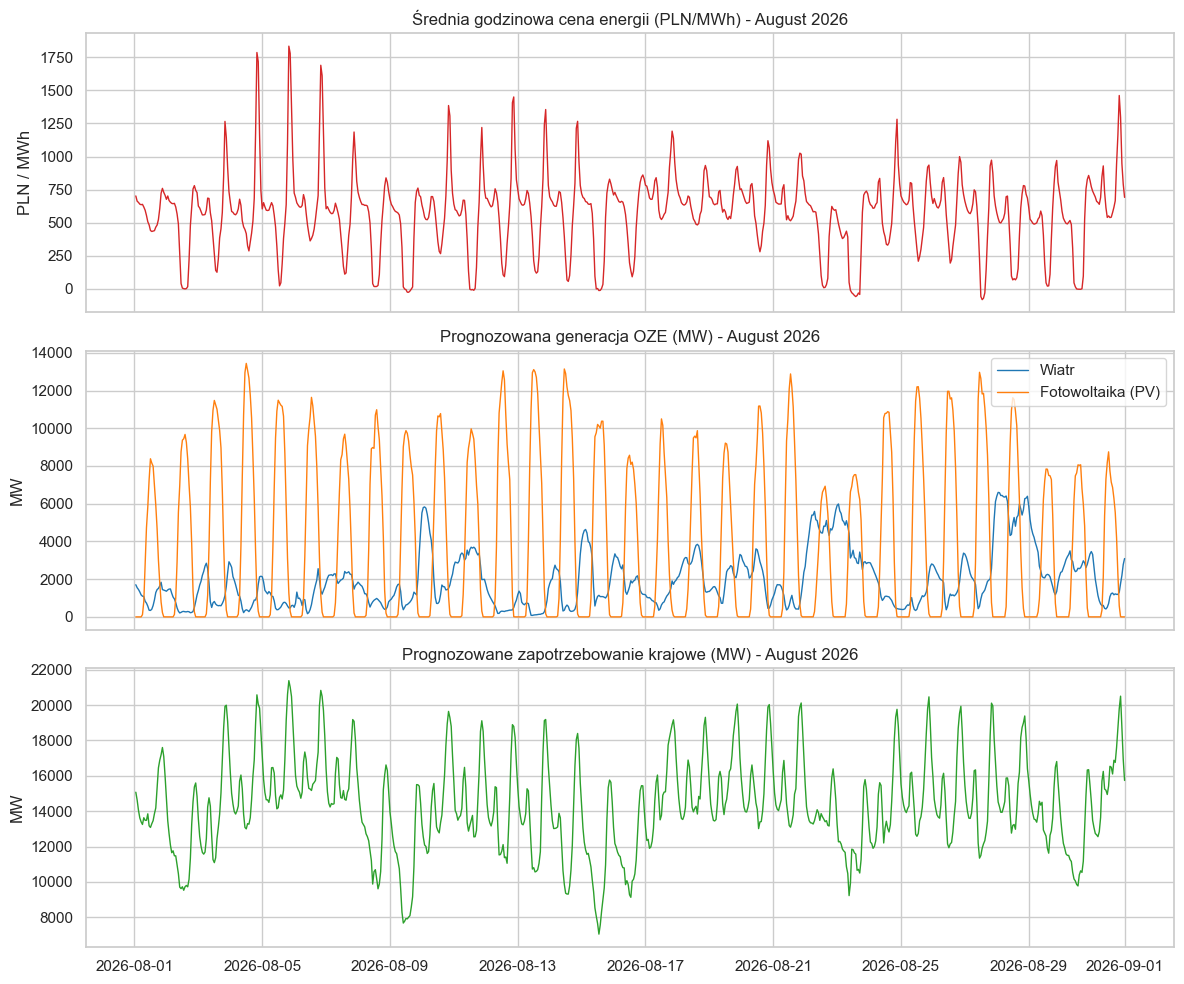

In [5]:
# 3 Wizualna weryfikacja danych
sns.set_theme(style="whitegrid")

miesiac_nazwa = df_merged['datetime'].dt.to_period('M').mode()[0].strftime('%B %Y')

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

axes[0].plot(df_merged['datetime'], df_merged['rce_pln'], color='tab:red', lw=1)
axes[0].set_title(f'Średnia godzinowa cena energii (PLN/MWh) - {miesiac_nazwa}')
axes[0].set_ylabel('PLN / MWh')

axes[1].plot(df_merged['datetime'], df_merged['fcst_wi_tot_gen'], color='tab:blue', label='Wiatr', lw=1)
axes[1].plot(df_merged['datetime'], df_merged['fcst_pv_tot_gen'], color='tab:orange', label='Fotowoltaika (PV)', lw=1)
axes[1].set_title(f'Prognozowana generacja OZE (MW) - {miesiac_nazwa}')
axes[1].set_ylabel('MW')
axes[1].legend(loc='upper right')

axes[2].plot(df_merged['datetime'], df_merged['grid_demand_fcst'], color='tab:green', lw=1)
axes[2].set_title(f'Prognozowane zapotrzebowanie krajowe (MW) - {miesiac_nazwa}')
axes[2].set_ylabel('MW')

plt.tight_layout()
plt.show()

In [6]:
# 4 Podstawowe statystyki

mean_price = df_merged['rce_pln'].mean()

total_wind_gen = df_merged['fcst_wi_tot_gen'].sum()
total_pv_gen = df_merged['fcst_pv_tot_gen'].sum()

print("=" * 60)
print(f"WYNIKI - {miesiac_nazwa}")
print("=" * 60)
print(f"Średnia cena energii:                  {mean_price:.2f} PLN/MWh")
print(f"Suma generacji z wiatru (Wind):         {total_wind_gen:,.2f} MWh")
print(f"Suma generacji z fotowoltaiki (PV):     {total_pv_gen:,.2f} MWh")
print("=" * 60)

WYNIKI - August 2026
Średnia cena energii:                  575.87 PLN/MWh
Suma generacji z wiatru (Wind):         1,449,850.00 MWh
Suma generacji z fotowoltaiki (PV):     2,873,944.00 MWh


In [7]:
# 5 Wyliczenie przychodu i Capture Price

# Przychód godzinowy: cena [PLN/MWh] * generacja [MW * 1h = MWh]
df_merged['revenue_wind'] = df_merged['rce_pln'] * df_merged['fcst_wi_tot_gen']
df_merged['revenue_pv'] = df_merged['rce_pln'] * df_merged['fcst_pv_tot_gen']

total_revenue_wind = df_merged['revenue_wind'].sum()
total_revenue_pv = df_merged['revenue_pv'].sum()

# Capture Price (średnia cena faktycznie uzyskana) = suma przychodów / suma generacji
capture_price_wind = total_revenue_wind / total_wind_gen if total_wind_gen > 0 else 0
capture_price_pv = total_revenue_pv / total_pv_gen if total_pv_gen > 0 else 0

print("=" * 50)
print(f"WYNIKI - {miesiac_nazwa}")
print("=" * 50)
print(f"Suma przychodu z wiatru:                {total_revenue_wind:,.2f} PLN")
print(f"Suma przychodu z PV:                    {total_revenue_pv:,.2f} PLN")
print(f"Suma przychodu OZE razem:               {total_revenue_wind + total_revenue_pv:,.2f} PLN")
print(f"Średnia cena rynkowa (Base):             {mean_price:.2f} PLN/MWh")
print(f"Capture Price (Wiatr):                   {capture_price_wind:.2f} PLN/MWh  (Różnica: {capture_price_wind - mean_price:.2f} PLN)")
print(f"Capture Price (PV):                      {capture_price_pv:.2f} PLN/MWh  (Różnica: {capture_price_pv - mean_price:.2f} PLN)")
print("=" * 50)

WYNIKI - August 2026
Suma przychodu z wiatru:                811,357,456.46 PLN
Suma przychodu z PV:                    1,033,507,118.76 PLN
Suma przychodu OZE razem:               1,844,864,575.22 PLN
Średnia cena rynkowa (Base):             575.87 PLN/MWh
Capture Price (Wiatr):                   559.61 PLN/MWh  (Różnica: -16.26 PLN)
Capture Price (PV):                      359.61 PLN/MWh  (Różnica: -216.26 PLN)


In [8]:
# 6 Weryfikacja godzin z ceną <= 0 PLN/MWh

negative_prices_df = df_merged[df_merged['rce_pln'] <= 0].copy()
num_negative_hours = len(negative_prices_df)
total_hours = len(df_merged)
percentage_negative = (num_negative_hours / total_hours) * 100

print("=" * 50)
print(f"WYNIKI - {miesiac_nazwa}")
print("=" * 50)
print(f"Liczba godzin z ceną <= 0 PLN: {num_negative_hours} ({percentage_negative:.1f}%)")

if num_negative_hours > 0:
    negative_prices_df['hour_of_day'] = negative_prices_df['datetime'].dt.hour
    hourly_distribution = negative_prices_df['hour_of_day'].value_counts().sort_index()

    avg_gen_pv_neg = negative_prices_df['fcst_pv_tot_gen'].mean()
    avg_gen_wi_neg = negative_prices_df['fcst_wi_tot_gen'].mean()
    avg_demand_neg = negative_prices_df['grid_demand_fcst'].mean()

    print(f"Średnia generacja PV:    {avg_gen_pv_neg:,.2f} MW")
    print(f"Średnia generacja Wiatr: {avg_gen_wi_neg:,.2f} MW")
    print(f"Średnie zapotrzebowanie: {avg_demand_neg:,.2f} MW")

print("=" * 50)

# Tabela: rozkład godzinowy cen <= 0
if num_negative_hours > 0:
    hourly_table = hourly_distribution.reset_index()
    hourly_table.columns = ['Godzina', 'Liczba dni z ceną <= 0']
    display(hourly_table.style.hide(axis='index'))

WYNIKI - August 2026
Liczba godzin z ceną <= 0 PLN: 28 (3.8%)
Średnia generacja PV:    8,889.68 MW
Średnia generacja Wiatr: 2,192.29 MW
Średnie zapotrzebowanie: 10,465.61 MW


Godzina,Liczba dni z ceną <= 0
10,1
11,2
12,5
13,6
14,6
15,5
16,2
17,1


In [10]:
# 7.1 Wskaźnik penetracji OZE
total_demand = df_merged['grid_demand_fcst'].sum()
wind_share_percentage = (total_wind_gen / total_demand) * 100
pv_share_percentage = (total_pv_gen / total_demand) * 100

print("=" * 50)
print(f"WSKAŹNIK PENETRACJI OZE - {miesiac_nazwa}")
print("=" * 50)
print(f"Całkowite zapotrzebowanie krajowe:      {total_demand:,.2f} MWh")
print(f"Generacja z wiatru:                     {total_wind_gen:,.2f} MWh")
print(f"Generacja z PV:                          {total_pv_gen:,.2f} MWh")
print(f"Pokrycie zapotrzebowania przez wiatr:    {wind_share_percentage:.2f}%")
print(f"Pokrycie zapotrzebowania przez PV:       {pv_share_percentage:.2f}%")
print(f"Pokrycie zapotrzebowania przez OZE razem: {wind_share_percentage + pv_share_percentage:.2f}%")
print("=" * 50)

df_merged['hour_of_day'] = df_merged['datetime'].dt.hour
profile_24h = df_merged.groupby('hour_of_day')[
    ['rce_pln', 'fcst_wi_tot_gen', 'fcst_pv_tot_gen', 'grid_demand_fcst']
].mean()
profile_24h_plot = pd.concat([profile_24h, profile_24h.loc[[0]].rename(index={0: 24})])

WSKAŹNIK PENETRACJI OZE - August 2026
Całkowite zapotrzebowanie krajowe:      10,652,039.00 MWh
Generacja z wiatru:                     1,449,850.00 MWh
Generacja z PV:                          2,873,944.00 MWh
Pokrycie zapotrzebowania przez wiatr:    13.61%
Pokrycie zapotrzebowania przez PV:       26.98%
Pokrycie zapotrzebowania przez OZE razem: 40.59%


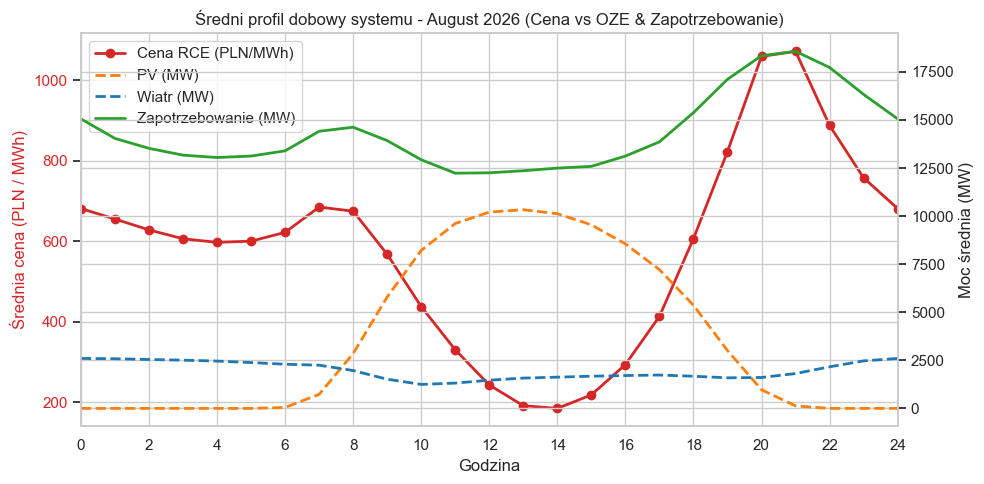

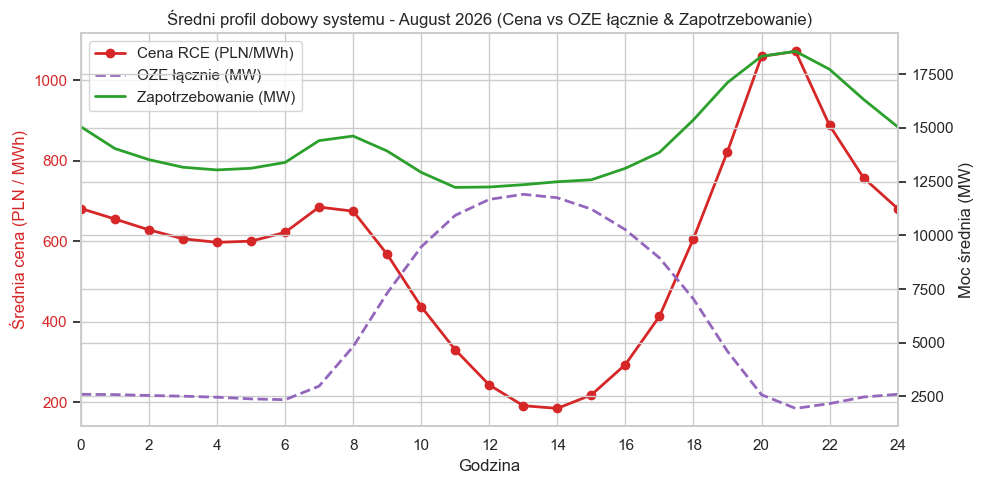

In [11]:
# 7.2 Wskaźnik penetracji OZE - Wykres
fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.set_xlabel('Godzina')
ax1.set_ylabel('Średnia cena (PLN / MWh)', color='tab:red')
line1 = ax1.plot(profile_24h_plot.index, profile_24h_plot['rce_pln'], color='tab:red', linewidth=2, marker='o', label='Cena RCE (PLN/MWh)')
ax1.tick_params(axis='y', labelcolor='tab:red')
ax1.set_xlim(0, 24)
ax1.set_xticks(range(0, 25, 2))

ax2 = ax1.twinx()
ax2.set_ylabel('Moc średnia (MW)')
line2 = ax2.plot(profile_24h_plot.index, profile_24h_plot['fcst_pv_tot_gen'], color='tab:orange', linewidth=2, linestyle='--', label='PV (MW)')
line3 = ax2.plot(profile_24h_plot.index, profile_24h_plot['fcst_wi_tot_gen'], color='tab:blue', linewidth=2, linestyle='--', label='Wiatr (MW)')
line4 = ax2.plot(profile_24h_plot.index, profile_24h_plot['grid_demand_fcst'], color='tab:green', linewidth=2, label='Zapotrzebowanie (MW)')

lines = line1 + line2 + line3 + line4
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')

plt.title(f'Średni profil dobowy systemu - {miesiac_nazwa} (Cena vs OZE & Zapotrzebowanie)')
fig.tight_layout()
plt.show()


# 7.3 Profil dobowy - OZE łącznie (Wiatr + PV) vs Cena i Zapotrzebowanie
profile_24h_plot['fcst_oze_tot_gen'] = profile_24h_plot['fcst_wi_tot_gen'] + profile_24h_plot['fcst_pv_tot_gen']

fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.set_xlabel('Godzina')
ax1.set_ylabel('Średnia cena (PLN / MWh)', color='tab:red')
line1 = ax1.plot(profile_24h_plot.index, profile_24h_plot['rce_pln'], color='tab:red', linewidth=2, marker='o', label='Cena RCE (PLN/MWh)')
ax1.tick_params(axis='y', labelcolor='tab:red')
ax1.set_xlim(0, 24)
ax1.set_xticks(range(0, 25, 2))

ax2 = ax1.twinx()
ax2.set_ylabel('Moc średnia (MW)')
line2 = ax2.plot(profile_24h_plot.index, profile_24h_plot['fcst_oze_tot_gen'], color='tab:purple', linewidth=2, linestyle='--', label='OZE łącznie (MW)')
line3 = ax2.plot(profile_24h_plot.index, profile_24h_plot['grid_demand_fcst'], color='tab:green', linewidth=2, label='Zapotrzebowanie (MW)')

lines = line1 + line2 + line3
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')

plt.title(f'Średni profil dobowy systemu - {miesiac_nazwa} (Cena vs OZE łącznie & Zapotrzebowanie)')
fig.tight_layout()
plt.show()

## Wnioski

**Średnia cena rynkowa (RCE) w sierpniu 2026 wyniosła 575,87 PLN/MWh.** Capture price dla energii wiatrowej wyniósł 559,61 PLN/MWh, niższy od średniej ceny rynkowej o 2,8%. W przypadku PV capture price wyniósł 359,61 PLN/MWh, tj. o 37,6% mniej niż średnia RCE.

**Głównym czynnikiem różnicy jest efekt kanibalizacji cenowej PV.** Instalacje fotowoltaiczne w kraju generują energię jednocześnie, przede wszystkim w godzinach okołopołudniowych. Koncentracja produkcji w tym samym przedziale czasowym zwiększa podaż energii w godzinach, w których ceny rynkowe są już relatywnie najniższe. Profil generacji wiatrowej jest istotnie mniej skorelowany czasowo, dzięki czemu energia wiatrowa w mniejszym stopniu wpływa na obniżenie własnej ceny realizowanej przez producentów.

**Ceny ≤ 0 PLN/MWh wystąpiły przez 28 godzin, tj. 3,8% miesiąca, wyłącznie w przedziale 10:00–17:00.** Okno to niemal dokładnie pokrywało się ze szczytem generacji PV. Średnia generacja PV w tych godzinach wynosiła ok. 8 890 MW przy zapotrzebowaniu na poziomie ok. 10 466 MW, co oznacza, że sama fotowoltaika pokrywała ok. 85% zapotrzebowania. Rozkład godzinowy wskazuje na szczególnie wysoką koncentrację cen ≤ 0 PLN/MWh w godzinach 13:00–14:00 — w każdej z tych godzin odnotowano 6 dni z ceną ≤ 0 PLN/MWh w ciągu miesiąca.

**Penetracja OZE w strukturze zapotrzebowania w sierpniu 2026 wyniosła 40,59%.** Fotowoltaika odpowiadała za 26,98% zapotrzebowania, a wiatr za 13,61%. Udział PV był zatem wyraźnie wyższy niż udział wiatru, co jest spójne z charakterystyką sezonową sierpnia. Profil dobowy potwierdza, że w godzinach szczytowej generacji PV udział OZE w pokryciu zapotrzebowania osiąga najwyższe poziomy, co koreluje ze spadkami cen obserwowanymi w tych samych godzinach.

**Zastrzeżenie metodologiczne:** przedstawione wyniki opierają się na danych *prognozowanych* (`fcst_*`) publikowanych przez PSE, a nie na zmierzonej rzeczywistej generacji i zapotrzebowaniu. Rzeczywiste wolumeny mogły nieznacznie różnić się od wartości prognozowanych, m.in. w wyniku odchyleń pogodowych, co mogło mieć wpływ na rzeczywisty, zrealizowany wynik finansowy.